In [72]:
!pip install xgboost pandas scikit-learn

In [73]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Load the converted CSV file
df = pd.read_csv('football_train_data.csv')

print("Dataset Shape (Rows, Columns):", df.shape)

# 2. Define your target variable 
target_col = 'FTR' 

# Drop non-numeric metadata and the target from your feature matrix
X = df.drop(columns=[target_col, 'HomeTeam', 'AwayTeam', 'Date'], errors='ignore')
y = df[target_col]

# Convert text-based targets (like 'H', 'D', 'A') into numeric codes for XGBoost
if y.dtype == 'object':
    y = y.astype('category').cat.codes

# 3. Split data into training (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialise and train the XGBoost classifier
model = xgb.XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42
)

model.fit(X_train, y_train)

# 5. Evaluate the model performance
preds = model.predict(X_val)
print("Baseline Validation Accuracy:", accuracy_score(y_val, preds))

Dataset Shape (Rows, Columns): (37824, 90)
Baseline Validation Accuracy: 0.561929940515532


In [74]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Load dataset
df = pd.read_csv('football_train_data.csv')
target_col = 'FTR'

# 2. Automatically identify and drop columns from competing bookmakers (GB, IW, LB, SO, SB, WH)
# while keeping match stats and Bet365 odds intact
other_bookie_prefixes = ('GB', 'IW', 'LB', 'SO', 'SB', 'WH')
cols_to_drop = [col for col in df.columns if col.startswith(other_bookie_prefixes)]

# Also drop metadata/target
metadata_cols = [target_col, 'HomeTeam', 'AwayTeam', 'Date']
drop_list = list(set(cols_to_drop + metadata_cols))

# 3. Create feature matrix X and target y
X = df.drop(columns=[col for col in drop_list if col in df.columns], errors='ignore')
y = df[target_col]

if y.dtype == 'object':
    y = y.astype('category').cat.codes

# 4. Split data (80/20 train/validation)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Train model with only Bet365 odds and match stats
model_b365 = xgb.XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42
)

model_b365.fit(X_train, y_train)

# 6. Evaluate
preds_b365 = model_b365.predict(X_val)
print("Remaining Feature Count:", X.shape[1])
print("Validation Accuracy (Bet365 Only):", accuracy_score(y_val, preds_b365))

Remaining Feature Count: 63
Validation Accuracy (Bet365 Only): 0.5612690019828156


In [75]:
# Pure Betting Odds Only
odds_cols = [c for c in X.columns if 'B365' in c or '365' in c]
X_odds = X[odds_cols]

X_tr_o, X_va_o, y_tr_o, y_va_o = train_test_split(X_odds, y, test_size=0.2, random_state=42)
model_odds = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_odds.fit(X_tr_o, y_tr_o)
print("Odds-Only Accuracy:", accuracy_score(y_va_o, model_odds.predict(X_va_o)))

# Pure Match Stats Only
stats_cols = [c for c in X.columns if c not in odds_cols]
X_stats = X[stats_cols]

X_tr_s, X_va_s, y_tr_s, y_va_s = train_test_split(X_stats, y, test_size=0.2, random_state=42)
model_stats = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_stats.fit(X_tr_s, y_tr_s)
print("Stats-Only Accuracy:", accuracy_score(y_va_s, model_stats.predict(X_va_s)))

Odds-Only Accuracy: 0.46226040978189026
Stats-Only Accuracy: 0.5614011896893589


In [76]:
import pandas as pd

# Get feature importance ranking
importances = pd.Series(model_b365.feature_importances_, index=X.columns).sort_values(ascending=False)

print("--- Top 10 Most Important Features ---")
print(importances.head(10))

print("\n--- Bottom 10 Least Important Features ---")
print(importances.tail(10))

# Drop features with 0 or near-zero importance
top_features = importances[importances > 0.005].index
X_top = X[top_features]

X_tr_t, X_va_t, y_tr_t, y_va_t = train_test_split(X_top, y, test_size=0.2, random_state=42)
model_top = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_top.fit(X_tr_t, y_tr_t)
print("\nPruned Features Accuracy:", accuracy_score(y_va_t, model_top.predict(X_va_t)))

--- Top 10 Most Important Features ---
AST      0.092147
HST      0.091445
B365A    0.039507
AR       0.035294
B365H    0.034552
HC       0.030416
AC       0.027316
HR       0.027245
BWA      0.020166
SJA      0.018349
dtype: float32

--- Bottom 10 Least Important Features ---
X1XBD      0.008977
BFEH       0.008772
BVH        0.008695
BFDD       0.008671
BVD        0.008657
BFEAHA     0.008648
X1XBA      0.008407
BFE.2.5    0.008279
BMGMA      0.008238
CLD        0.007494
dtype: float32

Pruned Features Accuracy: 0.5611368142762723


In [77]:
from sklearn.metrics import classification_report, confusion_matrix

preds = model_b365.predict(X_val)
print("--- Classification Report ---")
print(classification_report(y_val, preds))

print("--- Confusion Matrix ---")
print(confusion_matrix(y_val, preds))

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.54      0.61      0.57      2231
           1       0.43      0.11      0.18      2061
           2       0.59      0.81      0.68      3273

    accuracy                           0.56      7565
   macro avg       0.52      0.51      0.48      7565
weighted avg       0.53      0.56      0.51      7565

--- Confusion Matrix ---
[[1360  160  711]
 [ 700  229 1132]
 [ 470  146 2657]]


In [78]:
X_eng = X.copy()

# Add relative performance features
if 'HS' in X.columns and 'AS' in X.columns:
    X_eng['Shot_Diff'] = X_eng['HS'] - X_eng['AS']
if 'HST' in X.columns and 'AST' in X.columns:
    X_eng['Target_Shot_Diff'] = X_eng['HST'] - X_eng['AST']
if 'HC' in X.columns and 'AC' in X.columns:
    X_eng['Corner_Diff'] = X_eng['HC'] - X_eng['AC']

# Train on engineered dataset
X_tr_e, X_va_e, y_tr_e, y_va_e = train_test_split(X_eng, y, test_size=0.2, random_state=42)
model_eng = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_eng.fit(X_tr_e, y_tr_e)
print("Engineered Features Accuracy:", accuracy_score(y_va_e, model_eng.predict(X_va_e)))

Engineered Features Accuracy: 0.5604758757435558


In [79]:
from sklearn.model_selection import cross_val_score, KFold
import xgboost as xgb

# 1. Initialise your model with all CPU cores enabled
model_cv = xgb.XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42,
    n_jobs=-1
)

# 2. Set up 5-Fold Cross Validation with shuffling
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Compute accuracy across all 5 folds automatically
cv_scores = cross_val_score(model_cv, X, y, cv=kf, scoring='accuracy', n_jobs=-1)

print("Accuracy scores for each fold:", [f"{score:.4f}" for score in cv_scores])
print(f"Mean Cross-Validation Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

Accuracy scores for each fold: ['0.5613', '0.5581', '0.5603', '0.5462', '0.5543']
Mean Cross-Validation Accuracy: 0.5560 (+/- 0.0109)


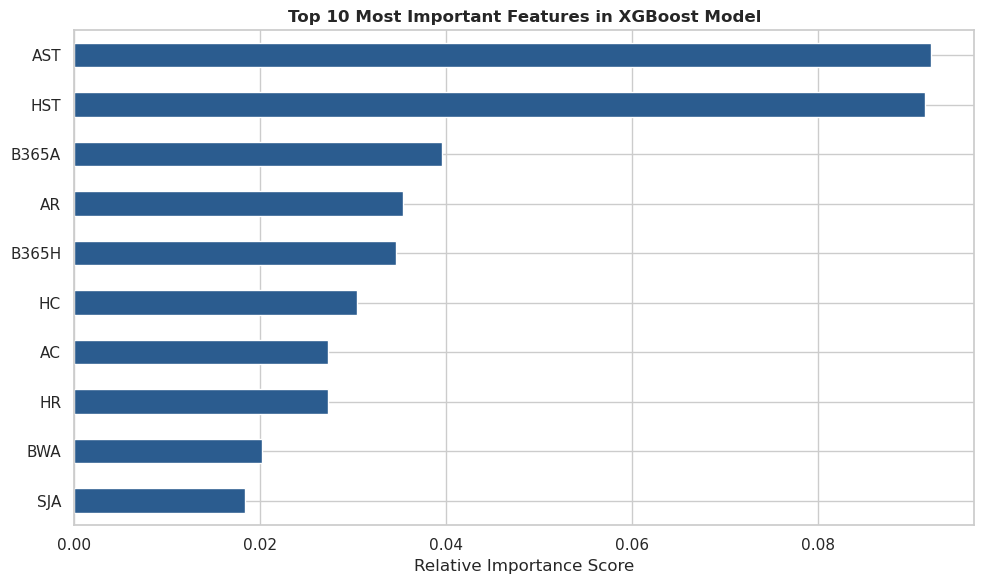

In [80]:
import matplotlib.pyplot as plt
import pandas as pd

# Get feature importances from your trained model
importances = pd.Series(model_b365.feature_importances_, index=X.columns)

# Plot top 10 features horizontally
plt.figure(figsize=(10, 6))
importances.nlargest(10).plot(kind='barh', color='#2b5c8f')
plt.title('Top 10 Most Important Features in XGBoost Model', fontsize=12, fontweight='bold')
plt.xlabel('Relative Importance Score')
plt.gca().invert_yaxis()  # Put the highest at the top
plt.tight_layout()
plt.show()

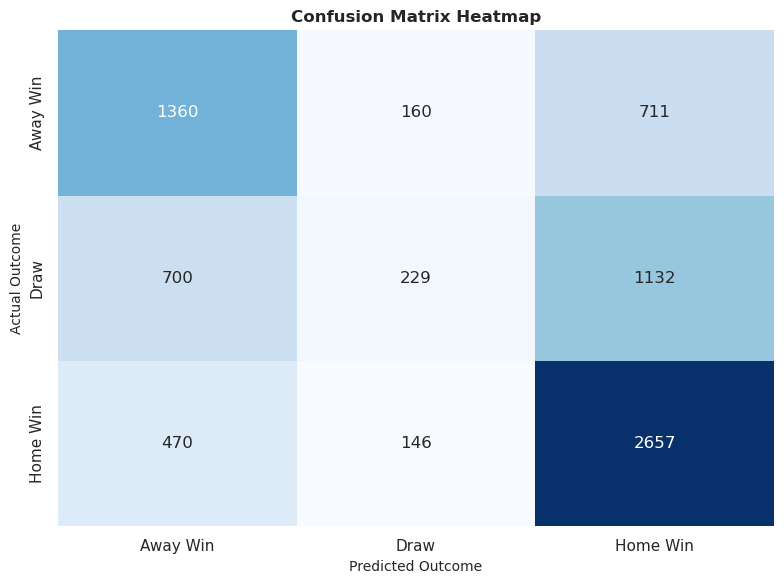

In [81]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_val, preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Away Win', 'Draw', 'Home Win'],
            yticklabels=['Away Win', 'Draw', 'Home Win'])
plt.title('Confusion Matrix Heatmap', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Outcome', fontsize=10)
plt.ylabel('Actual Outcome', fontsize=10)
plt.tight_layout()
plt.show()

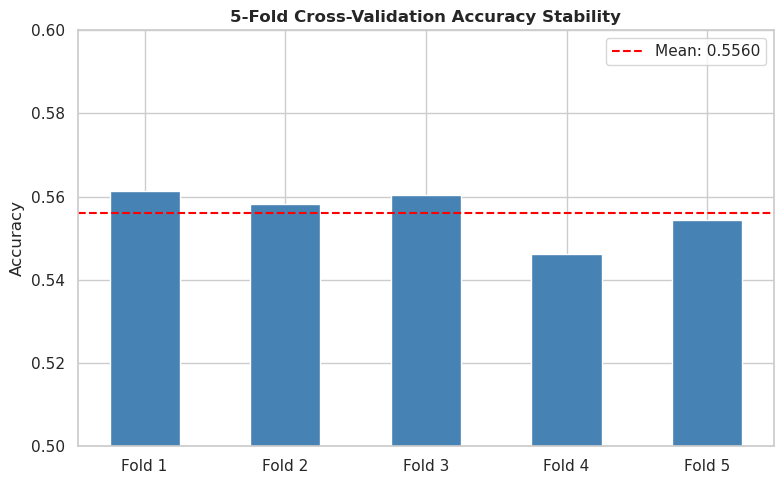

In [82]:
plt.figure(figsize=(8, 5))
folds = [f"Fold {i+1}" for i in range(len(cv_scores))]
plt.bar(folds, cv_scores, color='#4682B4', width=0.5)
plt.axhline(cv_scores.mean(), color='red', linestyle='--', label=f'Mean: {cv_scores.mean():.4f}')
plt.ylim(0.5, 0.6)  # Focus the axis around your accuracy range
plt.title('5-Fold Cross-Validation Accuracy Stability', fontsize=12, fontweight='bold')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

In [109]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Load the converted CSV file
df = pd.read_csv('football_test_data.csv')

print("Dataset Shape (Rows, Columns):", df.shape)

# 2. Define your target variable 
target_col = 'FTR' 

# Drop non-numeric metadata and the target from your feature matrix
X = df.drop(columns=[target_col, 'HomeTeam', 'AwayTeam', 'Date'], errors='ignore')
y = df[target_col]

# Convert text-based targets (like 'H', 'D', 'A') into numeric codes for XGBoost
if y.dtype == 'object':
    y = y.astype('category').cat.codes

# 3. Split data into training (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialise and train the XGBoost classifier
model = xgb.XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42
)

model.fit(X_train, y_train)

# 5. Evaluate the model performance
preds = model.predict(X_val)
print("Test Accuracy:", accuracy_score(y_val, preds))

Dataset Shape (Rows, Columns): (8740, 90)
Test Accuracy: 0.5966819221967964


In [110]:
import pandas as pd
import xgboost as xgb
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

# 1. Define the 12 full-time match stats
ft_stats = [
    'HS',
    'AS',
    'HC',
    'AC',
    'HF',
    'AF',
    'HST',
    'AST',
    'HY',
    'AY',
    'HR',
    'AR',
]

# 2. Load training data
train_df = pd.read_csv('football_train_data.csv')

# Dynamically select all bookmaker odds columns (typically ending in H, D, A)
# while excluding non-odds columns that happen to end in those letters.
# Standard bookmaker prefixes: B365, BW, IW, WH, VC, PS, LB, SB, SJ, GB, BS, etc.
bookie_prefixes = (
    'B365',
    'BW',
    'IW',
    'WH',
    'VC',
    'PS',
    'LB',
    'SB',
    'SJ',
    'GB',
    'BS',
    'Max',
    'Avg',
    'Bb',
    'Betway',
    'BSI',
    'VCH',
    'PSE',
)
odds_cols = [
    col
    for col in train_df.columns
    if any(col.startswith(p) for p in bookie_prefixes)
    and col[-1] in ['H', 'D', 'A']
]

# Combine the 12 stats + all bookie odds
feature_cols = ft_stats + odds_cols

# 3. Create training feature matrix and target
X_train_multi = train_df[feature_cols]
y_train = train_df['FTR']

if y_train.dtype == 'object':
  y_train = y_train.astype('category').cat.codes

# Train the multi-bookie leaky model
model_multi_leaky = xgb.XGBClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42
)
model_multi_leaky.fit(X_train_multi, y_train)

# 4. Load and evaluate test data using the exact same feature set
# (Ensure test_df is loaded in your workspace)
X_test_multi = test_df[feature_cols]
y_test = test_df['FTR']

if y_test.dtype == 'object':
  y_test = y_test.astype('category').cat.codes

# Generate predictions and evaluate
y_pred_multi = model_multi_leaky.predict(X_test_multi)
test_acc_multi = accuracy_score(y_test, y_pred_multi)

print(
    f'Final Test Accuracy (12 FT Stats + All Bookmaker Odds):'
    f' {test_acc_multi:.4f}\n'
)
print('Classification Report:')
print(classification_report(y_test, y_pred_multi))

print('\nConfusion Matrix:')
print(confusion_matrix(y_test, y_pred_multi))

Final Test Accuracy (12 FT Stats + All Bookmaker Odds): 0.5978

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.68      0.62      2605
           1       0.36      0.09      0.14      2159
           2       0.63      0.82      0.72      3976

    accuracy                           0.60      8740
   macro avg       0.52      0.53      0.49      8740
weighted avg       0.55      0.60      0.55      8740


Confusion Matrix:
[[1763  165  677]
 [ 756  196 1207]
 [ 525  185 3266]]


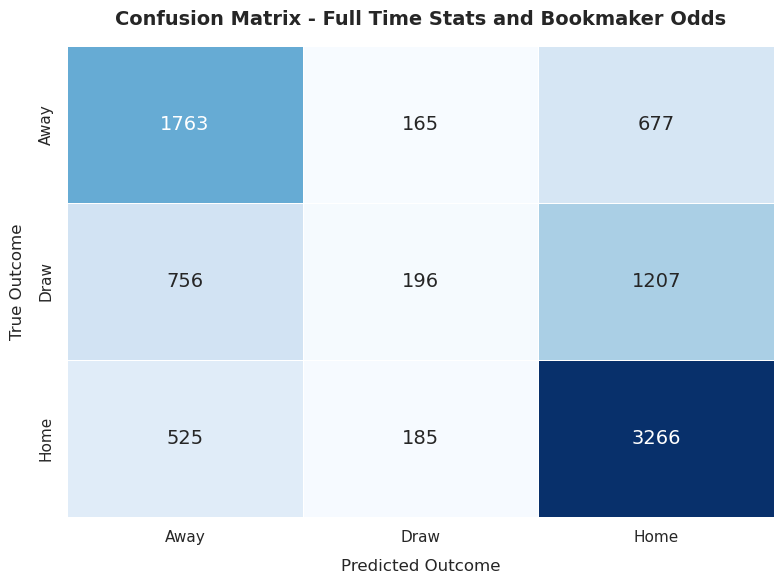

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred_multi)

# Set up the plot aesthetics
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    cbar=False,
    xticklabels=['Away', 'Draw', 'Home'], 
    yticklabels=['Away', 'Draw', 'Home'],
    linewidths=0.5,
    annot_kws={'size': 14}
)

# Add titles and labels
plt.title('Confusion Matrix - Full Time Stats and Bookmaker Odds', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Predicted Outcome', fontsize=12, labelpad=10)
plt.ylabel('True Outcome', fontsize=12, labelpad=10)

plt.tight_layout()
plt.show()

In [112]:
import pandas as pd
import xgboost as xgb
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

# 1. Map your exact 15 features to standard CSV column names
exact_15_features = [
    'HS',
    'AS',
    'HC',
    'AC',
    'HF',
    'AF',
    'HST',
    'AST',
    'HY',
    'AY',
    'HR',
    'AR',
    'B365H',
    'B365D',
    'B365A',
]

# 2. Load training data and select only these 15 features
train_df = pd.read_csv('football_train_data.csv')
X_train_15 = train_df[exact_15_features]
y_train = train_df['FTR']

if y_train.dtype == 'object':
  y_train = y_train.astype('category').cat.codes

# Train model on exactly 15 features
model_15 = xgb.XGBClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42
)
model_15.fit(X_train_15, y_train)

# 3. Load and evaluate test data using the exact same 15 features
# (Ensure test_df is loaded in your workspace)
X_test_15 = test_df[exact_15_features]
y_test = test_df['FTR']

if y_test.dtype == 'object':
  y_test = y_test.astype('category').cat.codes

y_pred_15 = model_15.predict(X_test_15)
test_acc_15 = accuracy_score(y_test, y_pred_15)

print(f'Final Test Accuracy (Full Time Statistics and Bet365 Odds): {test_acc_15:.4f}\n')
print('Classification Report:')
print(classification_report(y_test, y_pred_15))

print('\nConfusion Matrix:')
print(confusion_matrix(y_test, y_pred_15))

Final Test Accuracy (Full Time Statistics and Bet365 Odds): 0.6001

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.67      0.62      2605
           1       0.37      0.09      0.14      2159
           2       0.63      0.83      0.72      3976

    accuracy                           0.60      8740
   macro avg       0.53      0.53      0.49      8740
weighted avg       0.55      0.60      0.55      8740


Confusion Matrix:
[[1752  159  694]
 [ 759  186 1214]
 [ 511  158 3307]]


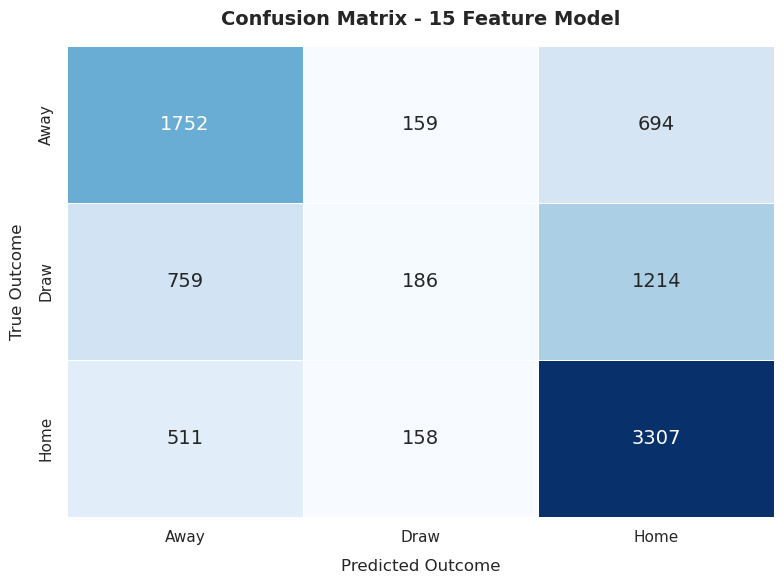

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred_15)

# Set up the plot aesthetics
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    cbar=False,
    xticklabels=['Away', 'Draw', 'Home'], 
    yticklabels=['Away', 'Draw', 'Home'],
    linewidths=0.5,
    annot_kws={'size': 14}
)

# Add titles and labels
plt.title('Confusion Matrix - 15 Feature Model', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Predicted Outcome', fontsize=12, labelpad=10)
plt.ylabel('True Outcome', fontsize=12, labelpad=10)

plt.tight_layout()
plt.show()

In [114]:
# Align test data to the exact pre-match features expected by your odds model
X_test_clean = test_df[model_odds.feature_names_in_]
y_test = test_df['FTR']

# Convert text-based targets to numeric codes if necessary
if y_test.dtype == 'object':
    y_test = y_test.astype('category').cat.codes

# Generate predictions using the clean pre-match model
y_pred = model_odds.predict(X_test_clean)

# Calculate honest final test accuracy
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Clean Final Test Accuracy (Odds Only): {test_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Clean Final Test Accuracy (Odds Only): 0.5331

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.55      0.52      2605
           1       0.21      0.01      0.02      2159
           2       0.56      0.81      0.66      3976

    accuracy                           0.53      8740
   macro avg       0.42      0.46      0.40      8740
weighted avg       0.45      0.53      0.46      8740


Confusion Matrix:
[[1429   20 1156]
 [ 728   23 1408]
 [ 704   65 3207]]


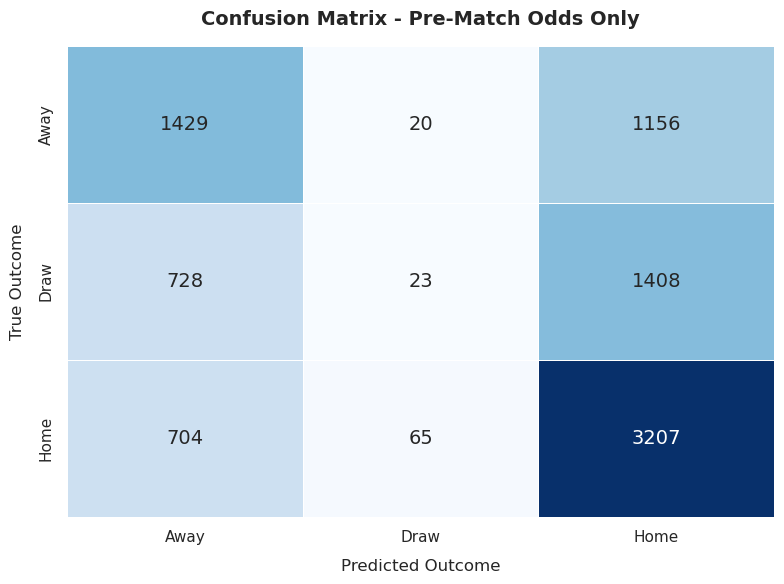

In [115]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Set up the plot aesthetics
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    cbar=False,
    xticklabels=['Away', 'Draw', 'Home'], 
    yticklabels=['Away', 'Draw', 'Home'],
    linewidths=0.5,
    annot_kws={'size': 14}
)

# Add titles and labels
plt.title('Confusion Matrix - Pre-Match Odds Only', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Predicted Outcome', fontsize=12, labelpad=10)
plt.ylabel('True Outcome', fontsize=12, labelpad=10)

plt.tight_layout()
plt.show()

In [116]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from xgboost import XGBClassifier

# 1. Define the Bet365 odds columns explicitly
b365_cols = ['B365H', 'B365D', 'B365A']

# 2. Train a clean model using ONLY Bet365 training data
X_tr_b365 = X_tr_o[b365_cols]
model_b365 = XGBClassifier(random_state=42, eval_metric='mlogloss')
model_b365.fit(X_tr_b365, y_tr_o)

# 3. Align test data to the exact Bet365 pre-match features
X_test_clean = test_df[b365_cols]
y_test = test_df['FTR']

# Convert text-based targets to numeric codes if necessary
if y_test.dtype == 'object':
  y_test = y_test.astype('category').cat.codes

# Generate predictions using the Bet365-only model
y_pred = model_b365.predict(X_test_clean)

# Calculate honest final test accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print(f'Clean Final Test Accuracy (Bet365 Only): {test_accuracy:.4f}\n')
print('Classification Report:')
print(classification_report(y_test, y_pred))

print('\nConfusion Matrix:')
print(confusion_matrix(y_test, y_pred))

Clean Final Test Accuracy (Bet365 Only): 0.5143

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.48      0.49      2605
           1       0.22      0.04      0.07      2159
           2       0.54      0.79      0.64      3976

    accuracy                           0.51      8740
   macro avg       0.42      0.44      0.40      8740
weighted avg       0.45      0.51      0.46      8740


Confusion Matrix:
[[1244  130 1231]
 [ 623   93 1443]
 [ 617  201 3158]]


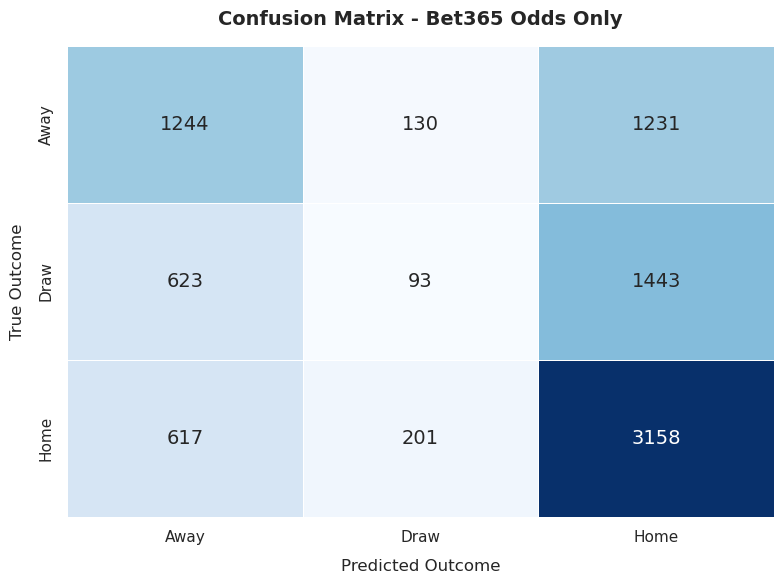

In [117]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Set up the plot aesthetics
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    cbar=False,
    xticklabels=['Away', 'Draw', 'Home'], 
    yticklabels=['Away', 'Draw', 'Home'],
    linewidths=0.5,
    annot_kws={'size': 14}
)

# Add titles and labels
plt.title('Confusion Matrix - Bet365 Odds Only', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Predicted Outcome', fontsize=12, labelpad=10)
plt.ylabel('True Outcome', fontsize=12, labelpad=10)

plt.tight_layout()
plt.show()

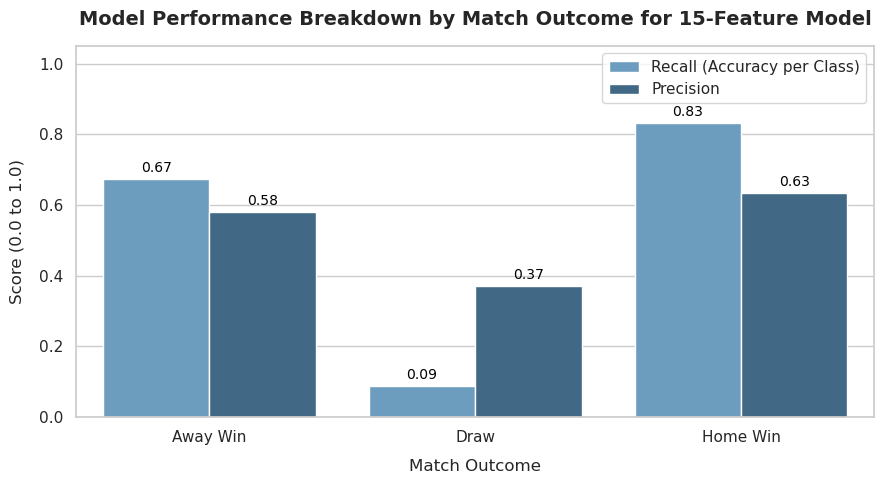

In [118]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

# Compute metrics for each class
precision, recall, f1, support = precision_recall_fscore_support(y_test, y_pred_15)

# Prepare data for plotting
metrics_df = pd.DataFrame({
    'Outcome': ['Away Win', 'Draw', 'Home Win'] * 2,
    'Score': list(recall) + list(precision),
    'Metric Type': ['Recall (Accuracy per Class)'] * 3 + ['Precision'] * 3
})

# Set up the plot aesthetics
plt.figure(figsize=(9, 5))
sns.set_theme(style="whitegrid")
ax = sns.barplot(
    x='Outcome', 
    y='Score', 
    hue='Metric Type', 
    data=metrics_df, 
    palette='Blues_d'
)

# Add titles, labels, and limits
plt.title('Model Performance Breakdown by Match Outcome for 15-Feature Model', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Match Outcome', fontsize=12, labelpad=10)
plt.ylabel('Score (0.0 to 1.0)', fontsize=12, labelpad=10)
plt.ylim(0, 1.05)

# Add numeric data labels on top of each bar for clarity
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{height:.2f}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', 
            va='bottom',
            fontsize=10, 
            color='black',
            xytext=(0, 3),
            textcoords='offset points'
        )

plt.legend(title='', loc='upper right')
plt.tight_layout()
plt.show()

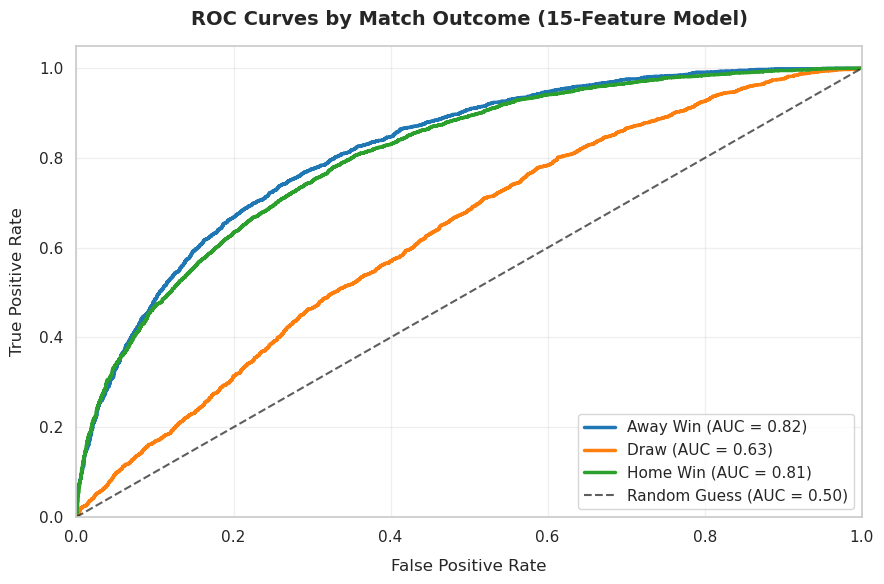

In [119]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_curve
from sklearn.preprocessing import label_binarize

# Ensure X_test_15 and y_test are defined with your 15 features
exact_15_features = [
    'HS',
    'AS',
    'HC',
    'AC',
    'HF',
    'AF',
    'HST',
    'AST',
    'HY',
    'AY',
    'HR',
    'AR',
    'B365H',
    'B365D',
    'B365A',
]
X_test_15 = test_df[exact_15_features]

# Convert y_test to numeric integer codes if it is currently strings ('H', 'D', 'A')
y_test_num = (
    test_df['FTR'].astype('category').cat.codes
    if test_df['FTR'].dtype == 'object'
    else test_df['FTR']
)

# 1. Binarize the test labels for multi-class ROC calculation (0: Away, 1: Draw, 2: Home)
y_test_bin = label_binarize(y_test_num, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

# 2. Get predicted probabilities from your 15-feature model
y_score = model_15.predict_proba(X_test_15)

# 3. Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
class_names = ['Away Win', 'Draw', 'Home Win']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

plt.figure(figsize=(9, 6))

for i in range(n_classes):
  fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
  roc_auc[i] = auc(fpr[i], tpr[i])
  plt.plot(
      fpr[i],
      tpr[i],
      color=colors[i],
      lw=2.5,
      label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})',
  )

# Plot diagonal reference line for random guessing (AUC = 0.50)
plt.plot(
    [0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7, label='Random Guess (AUC = 0.50)'
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, labelpad=10)
plt.ylabel('True Positive Rate', fontsize=12, labelpad=10)
plt.title(
    'ROC Curves by Match Outcome (15-Feature Model)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.legend(loc='lower right', fontsize=11, frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

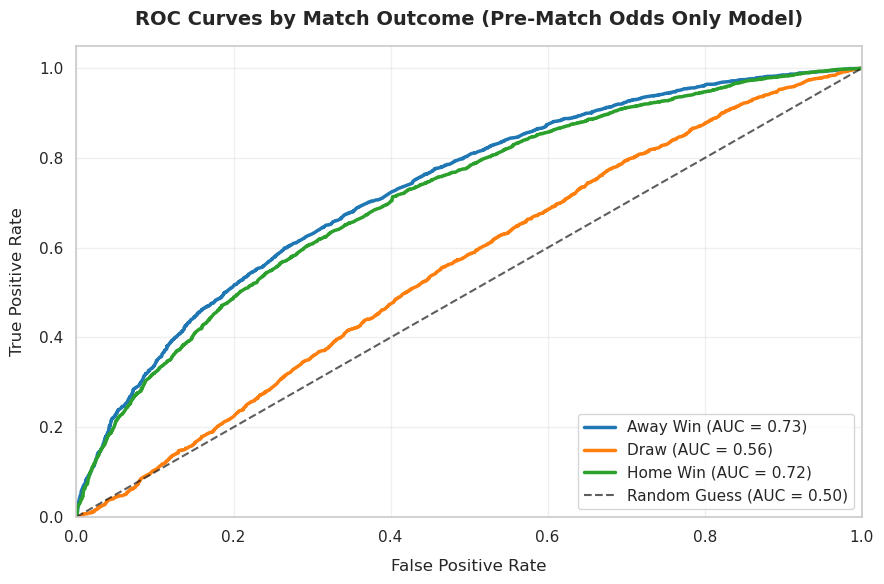

In [120]:
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import auc, roc_curve
from sklearn.preprocessing import label_binarize

# 1. Define pre-match odds features and prepare datasets
odds_features = ['B365H', 'B365D', 'B365A']
X_train_odds = train_df[odds_features]
X_test_odds = test_df[odds_features]

y_train_num = (
    train_df['FTR'].astype('category').cat.codes
    if train_df['FTR'].dtype == 'object'
    else train_df['FTR']
)
y_test_num = (
    test_df['FTR'].astype('category').cat.codes
    if test_df['FTR'].dtype == 'object'
    else test_df['FTR']
)

# Train the pre-match odds model
model_odds = xgb.XGBClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42
)
model_odds.fit(X_train_odds, y_train_num)

# 2. Binarize the test labels for multi-class ROC calculation (0: Away, 1: Draw, 2: Home)
y_test_bin = label_binarize(y_test_num, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

# 3. Get predicted probabilities from your pre-match odds model
y_score = model_odds.predict_proba(X_test_odds)

# 4. Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
class_names = ['Away Win', 'Draw', 'Home Win']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

plt.figure(figsize=(9, 6))

for i in range(n_classes):
  fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
  roc_auc[i] = auc(fpr[i], tpr[i])
  plt.plot(
      fpr[i],
      tpr[i],
      color=colors[i],
      lw=2.5,
      label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})',
  )

# Plot diagonal reference line for random guessing (AUC = 0.50)
plt.plot(
    [0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7, label='Random Guess (AUC = 0.50)'
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, labelpad=10)
plt.ylabel('True Positive Rate', fontsize=12, labelpad=10)
plt.title(
    'ROC Curves by Match Outcome (Pre-Match Odds Only Model)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.legend(loc='lower right', fontsize=11, frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [121]:
from sklearn.metrics import accuracy_score, log_loss

# Ensure targets are properly encoded
y_test_num = (
    test_df['FTR'].astype('category').cat.codes
    if test_df['FTR'].dtype == 'object'
    else test_df['FTR']
)

# 1. Pre-Match Odds Only Model Evaluation
odds_features = ['B365H', 'B365D', 'B365A']
y_pred_odds = model_odds.predict(test_df[odds_features])
y_prob_odds = model_odds.predict_proba(test_df[odds_features])

acc_odds = accuracy_score(y_test_num, y_pred_odds)
loss_odds = log_loss(y_test_num, y_prob_odds)

# 2. Strict 15-Feature Model Evaluation
exact_15_features = [
    'HS',
    'AS',
    'HC',
    'AC',
    'HF',
    'AF',
    'HST',
    'AST',
    'HY',
    'AY',
    'HR',
    'AR',
    'B365H',
    'B365D',
    'B365A',
]
y_pred_15 = model_15.predict(test_df[exact_15_features])
y_prob_15 = model_15.predict_proba(test_df[exact_15_features])

acc_15 = accuracy_score(y_test_num, y_pred_15)
loss_15 = log_loss(y_test_num, y_prob_15)

# 3. Print Structured Summary Table
print('=' * 65)
print(f"{'Model Architecture':<32} | {'Accuracy':<10} | {'Log Loss':<10}")
print('=' * 65)
print(
    f"{'Pre-Match Odds Only':<32} | {acc_odds * 100:6.2f}%    |"
    f' {loss_odds:8.4f}'
)
print(
    f"{'15-Feature Model':<32} | {acc_15 * 100:6.2f}%    |"
    f' {loss_15:8.4f}'
)
print('=' * 65)

Model Architecture               | Accuracy   | Log Loss  
Pre-Match Odds Only              |  53.31%    |   0.9852
15-Feature Model                 |  60.01%    |   0.8646


In [122]:
from sklearn.metrics import classification_report

# Ensure test targets are correctly encoded
y_test_num = (
    test_df['FTR'].astype('category').cat.codes
    if test_df['FTR'].dtype == 'object'
    else test_df['FTR']
)
target_names = ['Away Win (A)', 'Draw (D)', 'Home Win (H)']

print('=' * 65)
print('PER-CLASS PERFORMANCE BREAKDOWN')
print('=' * 65)

# 1. Strict 15-Feature Model Breakdown
exact_15_features = [
    'HS',
    'AS',
    'HC',
    'AC',
    'HF',
    'AF',
    'HST',
    'AST',
    'HY',
    'AY',
    'HR',
    'AR',
    'B365H',
    'B365D',
    'B365A',
]
y_pred_15 = model_15.predict(test_df[exact_15_features])

print('\n[ Model: 15-Feature ]')
print(
    classification_report(
        y_test_num, y_pred_15, target_names=target_names, digits=4
    )
)
print('-' * 65)

# 2. Pre-Match Odds Only Model Breakdown
odds_features = ['B365H', 'B365D', 'B365A']
y_pred_odds = model_odds.predict(test_df[odds_features])

print('\n[ Model: Pre-Match Odds Only ]')
print(
    classification_report(
        y_test_num, y_pred_odds, target_names=target_names, digits=4
    )
)
print('=' * 65)

PER-CLASS PERFORMANCE BREAKDOWN

[ Model: 15-Feature ]
              precision    recall  f1-score   support

Away Win (A)     0.5797    0.6726    0.6227      2605
    Draw (D)     0.3698    0.0862    0.1397      2159
Home Win (H)     0.6341    0.8317    0.7196      3976

    accuracy                         0.6001      8740
   macro avg     0.5279    0.5301    0.4940      8740
weighted avg     0.5526    0.6001    0.5475      8740

-----------------------------------------------------------------

[ Model: Pre-Match Odds Only ]
              precision    recall  f1-score   support

Away Win (A)     0.4995    0.5486    0.5229      2605
    Draw (D)     0.2130    0.0107    0.0203      2159
Home Win (H)     0.5557    0.8066    0.6580      3976

    accuracy                         0.5331      8740
   macro avg     0.4227    0.4553    0.4004      8740
weighted avg     0.4543    0.5331    0.4602      8740

